# 05 — Spike anatomy: what caused the biggest price events?

**Step 1 (this notebook so far): find the events.** Later steps pull interconnector flows and unit output for
±3 hours around the 3–5 events you choose, and you write a 4–5 line desk-note story for each.

**What counts as an event.** Single intervals are the wrong unit — a spike is usually a run of high-priced intervals,
sometimes with a brief dip in the middle. So:
1. A **spike interval** is RRP ≥ `SPIKE_PRICE` ($5,000/MWh by default, roughly a quarter to a third of the cap)
2. Spike intervals in the same region less than `MERGE_GAP` apart (30 min) belong to the **same event**
3. Events are ranked by **event cost** = Σ RRP × energy over the spike intervals — the $ that changed hands at spike prices.
   This ranks a 2-hour run at $10,000 above a single interval at the cap, which is what matters to a retailer

The June 2022 suspension is excluded.

In [1]:
import pandas as pd

pd.set_option("display.float_format", "{:,.0f}".format)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

df = pd.read_parquet("../data/clean/nem_5min.parquet")
df = df[~df["is_suspension"]].copy()
df["mwh"] = df["TOTALDEMAND"] * 5 / 60
df["value"] = df["RRP"] * df["mwh"]

SPIKE_PRICE = 5_000                  # $/MWh
MERGE_GAP = pd.Timedelta(minutes=30)
MARKET_PRICE_CAP = {"FY22": 15_100, "FY23": 15_500, "FY24": 16_600, "FY25": 17_500, "FY26": 20_300, "FY27": 23_200}

In [2]:
def find_events(df, region):
    """Group one region's spike intervals into events and summarise each one."""
    s = df[(df["REGIONID"] == region) & (df["RRP"] >= SPIKE_PRICE)].sort_values("interval_start").copy()

    # A new event starts whenever the gap since the previous spike interval is MERGE_GAP or more
    gap = s["interval_start"].diff()
    s["event_id"] = (gap.isna() | (gap >= MERGE_GAP)).cumsum()

    s["cap"] = s["fy"].map(MARKET_PRICE_CAP)
    events = s.groupby("event_id").agg(
        start=("interval_start", "min"),
        end=("SETTLEMENTDATE", "max"),
        spike_intervals=("RRP", "size"),
        max_price=("RRP", "max"),
        mean_price=("RRP", "mean"),
        intervals_at_cap=("RRP", lambda p: (p >= s.loc[p.index, "cap"]).sum()),
        peak_demand=("TOTALDEMAND", "max"),
        min_available_gen=("AVAILABLEGENERATION", "min"),
        mean_net_interchange=("NETINTERCHANGE", "mean"),
        event_cost_m=("value", lambda v: v.sum() / 1e6),
    )
    events.insert(0, "region", region)
    events["duration_h"] = (events["end"] - events["start"]).dt.total_seconds() / 3600
    events["fy"] = s.groupby("event_id")["fy"].first()
    return events.sort_values("event_cost_m", ascending=False).reset_index(drop=True)


events = pd.concat([find_events(df, r) for r in ["NSW1", "SA1"]], ignore_index=True)
print(f"events with at least one interval >= ${SPIKE_PRICE:,}: {events.groupby('region').size().to_dict()}")

events with at least one interval >= $5,000: {'NSW1': 120, 'SA1': 139}


## The biggest events

`event_cost_m` is in $ million. `mean_net_interchange` < 0 means the region was **importing** on average during the event.
`spike_intervals` counts only intervals ≥ $5,000; `duration_h` runs from first to last, so it includes any brief dips.

In [3]:
COLS = ["region", "fy", "start", "end", "duration_h", "spike_intervals", "intervals_at_cap", "max_price",
        "mean_price", "peak_demand", "min_available_gen", "mean_net_interchange", "event_cost_m"]

top = events.sort_values("event_cost_m", ascending=False).groupby("region").head(10)
top[COLS].style.format({
    "duration_h": "{:.1f}", "max_price": "{:,.0f}", "mean_price": "{:,.0f}", "peak_demand": "{:,.0f}",
    "min_available_gen": "{:,.0f}", "mean_net_interchange": "{:,.0f}", "event_cost_m": "{:,.1f}",
    "start": "{:%Y-%m-%d %H:%M}", "end": "{:%Y-%m-%d %H:%M}",
}).hide(axis="index")

region,fy,start,end,duration_h,spike_intervals,intervals_at_cap,max_price,mean_price,peak_demand,min_available_gen,mean_net_interchange,event_cost_m
NSW1,FY24,2024-05-08 15:35,2024-05-08 19:50,4.2,48,1,"16,600","14,956","9,460","11,085",-519,535.0
NSW1,FY25,2025-06-26 16:45,2025-06-26 20:55,4.2,43,0,"16,142","11,139","11,795","12,059","-1,244",458.9
NSW1,FY25,2025-06-12 17:10,2025-06-12 20:35,3.4,35,0,"17,026","11,488","11,637","11,806",-596,381.0
NSW1,FY25,2024-11-07 16:20,2024-11-07 19:20,3.0,31,0,"16,100","13,045","8,899","10,771",-335,291.4
NSW1,FY25,2024-08-05 07:35,2024-08-05 09:15,1.7,19,0,"16,966","13,816","10,468","12,420",-885,225.8
NSW1,FY25,2024-11-27 14:25,2024-11-27 15:35,1.2,14,11,"17,500","17,393","11,303","11,914",-804,222.4
NSW1,FY25,2024-08-05 17:10,2024-08-05 18:40,1.5,14,2,"17,500","14,925","11,746","12,278","-1,031",200.4
NSW1,FY24,2024-05-08 06:30,2024-05-08 08:10,1.7,17,0,"16,432","14,826","8,383","10,118",-448,172.7
NSW1,FY24,2024-05-07 17:10,2024-05-07 18:30,1.3,15,0,"16,600","14,168","9,572","10,983",-600,166.4
SA1,FY26,2026-01-26 18:25,2026-01-26 21:40,3.2,35,3,"20,300","18,399","3,140","2,663",-491,161.3


## Did the other region spike at the same time?

If NSW and SA spike together, the cause is usually NEM-wide (heat across the south-east, a big coal unit out, gas shortage).
If only one region spikes, look for local causes: the interconnector hitting its limit, low local wind, a local outage.

In [4]:
spike_times = df.loc[df["RRP"] >= SPIKE_PRICE, ["REGIONID", "interval_start"]]
spiking = spike_times.groupby("interval_start")["REGIONID"].apply(set)


def other_region_overlap(row):
    """Share of this event's spike intervals in which the other region was also >= SPIKE_PRICE."""
    other = "SA1" if row["region"] == "NSW1" else "NSW1"
    times = spiking.loc[row["start"]:row["end"] - pd.Timedelta(minutes=5)]
    mine = times[times.apply(lambda r: row["region"] in r)]
    return (mine.apply(lambda r: other in r)).mean() if len(mine) else 0


top = top.assign(other_region_also_spiking=top.apply(other_region_overlap, axis=1))
top[["region", "start", "duration_h", "event_cost_m", "other_region_also_spiking"]].style.format({
    "duration_h": "{:.1f}", "event_cost_m": "{:,.1f}", "other_region_also_spiking": "{:.0%}",
    "start": "{:%Y-%m-%d %H:%M}",
}).hide(axis="index")

region,start,duration_h,event_cost_m,other_region_also_spiking
NSW1,2024-05-08 15:35,4.2,535.0,0%
NSW1,2025-06-26 16:45,4.2,458.9,100%
NSW1,2025-06-12 17:10,3.4,381.0,100%
NSW1,2024-11-07 16:20,3.0,291.4,0%
NSW1,2024-08-05 07:35,1.7,225.8,100%
NSW1,2024-11-27 14:25,1.2,222.4,0%
NSW1,2024-08-05 17:10,1.5,200.4,29%
NSW1,2024-05-08 06:30,1.7,172.7,0%
NSW1,2024-05-07 17:10,1.3,166.4,0%
SA1,2026-01-26 18:25,3.2,161.3,0%


## Events per year

In [5]:
events.pivot_table(index="fy", columns="region", values="event_cost_m", aggfunc=["size", "sum"]).rename(
    columns={"size": "events", "sum": "total_event_cost_m"})

events     total_event_cost_m    
region   NSW1 SA1               NSW1 SA1
fy                                      
FY22       16  30                446 178
FY23       20  39                512 196
FY24       20  20              1,363 150
FY25       48  33              2,788 505
FY26       16  16                434 320
FY27      NaN   1                NaN   4

## Pick your 3–5 events

Good case studies **differ from each other**, so the note covers several causes rather than one cause five times. Aim for:
- at least one **NSW** and one **SA** event
- at least one **SA-only** event (other region not spiking) — likely an interconnector or wind story
- at least one **joint** event — likely NEM-wide demand/supply
- ideally events from **different years and seasons**

The chosen events live in `EVENTS` in `src/download_events.py`, which downloads interconnector and unit data for ±3 hours around each.
To study a different event: add it there, re-run `src/download_events.py`, then re-run the cells below.

In [6]:
import sys
sys.path.append("../src")
from download_events import EVENTS, WINDOW

EVENTS

{'2022-08-26_SA1': ('SA1', '2022-08-26 06:30', '2022-08-26 08:30'),
 '2024-05-08_NSW1': ('NSW1', '2024-05-08 15:35', '2024-05-08 19:50'),
 '2024-11-27_NSW1': ('NSW1', '2024-11-27 14:25', '2024-11-27 15:35'),
 '2025-06-26_NSW1_SA1': ('NSW1', '2025-06-26 16:45', '2025-06-26 20:55'),
 '2026-01-26_SA1': ('SA1', '2026-01-26 18:25', '2026-01-26 21:40')}

## Step 2: event panels

**Data for each event** (±3 hours):
- price and demand from `data/clean/nem_5min.parquet`
- interconnector flows and limits (DISPATCHINTERCONNECTORRES)
- unit output (DISPATCH_UNIT_SCADA), grouped by fuel

**Unit → fuel.** Fuel comes from AEMO's current registration list. Units no longer on it are filled in two ways:
first, from another unit at the same station; then, from the manual list `RETIRED_STATIONS`. That list covers
Liddell (closed April 2023) and batteries that used separate "generate" and "charge" IDs before mid-2024.

**Signs.** `LOAD` units (battery charging under the old split IDs, pumped-hydro pumps) report consumption as positive,
so they are flipped to negative. Newer bidirectional batteries already report charging as negative.

**Not included:** rooftop solar. It isn't dispatched, so it has no SCADA. It shows up as lower operational demand instead.

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from chart_style import apply_style, save_chart, REGION_COLOR, SURFACE, INK, INK_2, MUTED, AXIS

apply_style()
EVENTS_DIR = "../data/raw/events"
clean = pd.read_parquet("../data/clean/nem_5min.parquet")

# Stations whose units have left AEMO's registration list
RETIRED_STATIONS = {
    "LIDDELL": "Coal",
    "HORNSDPR": "Battery", "LBBESS": "Battery", "DALNTH": "Battery", "TIBESS": "Battery", "TB2HYB": "Battery",
    "ADP": "Battery", "WALGBESS": "Battery", "RESS1": "Battery", "RESS2": "Battery", "DPNTBESS": "Battery",
}


def fuel_group(primary, descriptor):
    """Collapse AEMO's fuel fields into the groups used on the charts."""
    if pd.isna(primary) or primary == "-":
        return None
    if primary == "Battery Storage":
        return "Battery"
    if primary in ("Hydro", "Wind", "Solar"):
        return primary
    if primary == "Fossil":
        return "Coal" if descriptor in ("Black Coal", "Brown Coal") else "Gas & liquids"
    return "Other"


reg = pd.read_parquet(f"{EVENTS_DIR}/generators_and_loads.parquet")
reg["fuel"] = [fuel_group(p, d) for p, d in zip(reg["Fuel Source - Primary"], reg["Fuel Source - Descriptor"])]
fuel_by_duid = reg.dropna(subset=["fuel"]).drop_duplicates("DUID").set_index("DUID")["fuel"]

units = pd.read_parquet(f"{EVENTS_DIR}/dudetailsummary.parquet")
units["fuel"] = units["DUID"].map(fuel_by_duid)
station_fuel = units.dropna(subset=["fuel"]).drop_duplicates("STATIONID").set_index("STATIONID")["fuel"]
units["fuel"] = (units["fuel"]
                 .fillna(units["STATIONID"].map(station_fuel))
                 .fillna(units["STATIONID"].map(RETIRED_STATIONS))
                 .fillna("Other"))
units["sign"] = np.where(units["DISPATCHTYPE"] == "LOAD", -1, 1)
units.groupby(["REGIONID", "fuel"]).size().unstack("fuel").loc[["NSW1", "SA1"]]

fuel,Battery,Coal,Gas & liquids,Hydro,Other,Solar,Wind
REGIONID,,,,,,,
NSW1,32,20,24,24,75,49,20
SA1,34,NaN,38,1,37,20,26


In [8]:
# Interconnector direction: AEMO's positive flow is from the first region in the name to the second
IC_ENDS = {
    "NSW1-QLD1": ("NSW1", "QLD1"), "N-Q-MNSP1": ("NSW1", "QLD1"), "VIC1-NSW1": ("VIC1", "NSW1"),
    "V-SA": ("VIC1", "SA1"), "V-S-MNSP1": ("VIC1", "SA1"),
}
IC_NAME = {
    "NSW1-QLD1": "QNI (Qld)", "N-Q-MNSP1": "Terranora (Qld)", "VIC1-NSW1": "Vic–NSW",
    "V-SA": "Heywood (Vic)", "V-S-MNSP1": "Murraylink (Vic)",
}
FUELS = ["Coal", "Gas & liquids", "Hydro", "Wind", "Solar", "Battery", "Other"]
FUEL_COLOR = {
    "Coal": "#52514e", "Gas & liquids": "#eb6834", "Hydro": "#1baf7a", "Wind": "#008300",
    "Solar": "#eda100", "Battery": "#6250d6", "Other": "#e87ba4",
}
IC_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]


def to_start(settlementdate):
    return settlementdate - pd.Timedelta(minutes=5)


def imports_into(ic, region):
    """Flow into `region` on each of its interconnectors, with the matching limit (positive = importing)."""
    out = []
    for icid, (frm, to) in IC_ENDS.items():
        if region not in (frm, to):
            continue
        g = ic[ic["INTERCONNECTORID"] == icid].copy()
        if region == to:
            g["import_mw"], g["import_limit"] = g["MWFLOW"], g["EXPORTLIMIT"]
        else:
            g["import_mw"], g["import_limit"] = -g["MWFLOW"], -g["IMPORTLIMIT"]
        g["name"] = IC_NAME[icid]
        out.append(g)
    out = pd.concat(out)
    out["interval_start"] = to_start(out["SETTLEMENTDATE"])
    out["at_import_limit"] = (out["import_limit"] - out["import_mw"]).abs() < 1
    return out


def generation_by_fuel(scada, region):
    """MW by fuel group for one region, one row per interval (charging/pumping negative)."""
    s = scada.merge(units[["DUID", "REGIONID", "fuel", "sign"]], on="DUID", how="inner")
    s = s[s["REGIONID"] == region]
    s["mw"] = s["SCADAVALUE"] * s["sign"]
    s["interval_start"] = to_start(s["SETTLEMENTDATE"])
    return s.pivot_table(index="interval_start", columns="fuel", values="mw", aggfunc="sum").reindex(columns=FUELS).fillna(0)


def load_event(name, region):
    _, first_start, last_end = EVENTS[name]
    t0, t1 = pd.Timestamp(first_start) - WINDOW, pd.Timestamp(last_end) + WINDOW
    market = clean[(clean["SETTLEMENTDATE"] > t0) & (clean["SETTLEMENTDATE"] <= t1)]
    return {
        "name": name, "region": region,
        "spike_start": pd.Timestamp(first_start), "spike_end": to_start(pd.Timestamp(last_end)),
        "market": market,
        "imports": imports_into(pd.read_parquet(f"{EVENTS_DIR}/{name}_interconnectors.parquet"), region),
        "gen": generation_by_fuel(pd.read_parquet(f"{EVENTS_DIR}/{name}_scada.parquet"), region),
    }


def regions_for(name):
    return [r for r in ("NSW1", "SA1") if r in name]


loaded = {(name, r): load_event(name, r) for name in EVENTS for r in regions_for(name)}
list(loaded)

[('2022-08-26_SA1', 'SA1'),
 ('2024-05-08_NSW1', 'NSW1'),
 ('2024-11-27_NSW1', 'NSW1'),
 ('2025-06-26_NSW1_SA1', 'NSW1'),
 ('2025-06-26_NSW1_SA1', 'SA1'),
 ('2026-01-26_SA1', 'SA1')]

**Sanity check.** Dispatched generation in a region ≈ its operational demand + net exports.
The gap should be small (station loads, losses, small non-scheduled units). A big gap would mean the fuel mapping is missing units.

In [9]:
def balance_check(ev):
    m = ev["market"][ev["market"]["REGIONID"] == ev["region"]].set_index("interval_start")
    gen = ev["gen"].sum(axis=1)
    gap = gen - (m["TOTALDEMAND"] + m["NETINTERCHANGE"])
    unmapped = ev["gen"]["Other"].abs().mean()
    return pd.Series({"mean_gen_mw": gen.mean(), "mean_gap_mw": gap.mean(), "gap_%_of_gen": gap.mean() / gen.mean(),
                      "mean_other_mw": unmapped})


pd.DataFrame({k: balance_check(ev) for k, ev in loaded.items()}).T.style.format(
    {"mean_gen_mw": "{:,.0f}", "mean_gap_mw": "{:,.0f}", "gap_%_of_gen": "{:.1%}", "mean_other_mw": "{:,.0f}"})

In [10]:
def plot_event(ev):
    region, other = ev["region"], ("SA1" if ev["region"] == "NSW1" else "NSW1")
    m = ev["market"]
    mine = m[m["REGIONID"] == region].set_index("interval_start")
    theirs = m[m["REGIONID"] == other].set_index("interval_start")

    fig, axes = plt.subplots(4, 1, figsize=(11, 11), sharex=True,
                             gridspec_kw={"height_ratios": [1.1, 1, 1, 1.4]})
    for ax in axes:
        ax.axvspan(ev["spike_start"], ev["spike_end"], color="#f0efec", zorder=0, lw=0)

    # 1. Price
    ax = axes[0]
    ax.plot(mine.index, mine["RRP"], color=REGION_COLOR[region], lw=2, label=region)
    ax.plot(theirs.index, theirs["RRP"], color=REGION_COLOR[other], lw=1.2, alpha=0.8, label=other)
    ax.axhline(300, color=MUTED, lw=1, ls=(0, (4, 3)))
    ax.text(mine.index[0], 300, " $300", color=MUTED, fontsize=8.5, va="bottom")
    ax.set_ylabel("Price ($/MWh)")
    ax.set_title("Price")

    # 2. Demand vs available generation
    ax = axes[1]
    ax.plot(mine.index, mine["TOTALDEMAND"], color=REGION_COLOR[region], lw=2, label="Demand")
    ax.plot(mine.index, mine["AVAILABLEGENERATION"], color=REGION_COLOR[region], lw=1.5, ls=(0, (4, 3)),
            label="Available generation")
    ax.set_ylabel("MW")
    ax.set_title(f"{region} demand vs available generation")

    # 3. Imports into the region on each interconnector, with the import limit dashed
    ax = axes[2]
    for (name, g), color in zip(ev["imports"].groupby("name", sort=False), IC_COLORS):
        g = g.set_index("interval_start")
        ax.plot(g.index, g["import_mw"], color=color, lw=2, label=f"{name} flow")
        ax.plot(g.index, g["import_limit"], color=color, lw=1, ls=(0, (4, 3)), label=f"{name} import limit")
    ax.axhline(0, color=AXIS, lw=1)
    ax.set_ylabel("MW into region")
    ax.set_title(f"Interconnector flow into {region} (dashed = limit)")

    # 4. Generation by fuel: generation stacked above zero, charging/pumping below
    ax = axes[3]
    gen = ev["gen"]
    pos, neg = gen.clip(lower=0), gen.clip(upper=0)
    colors = [FUEL_COLOR[f] for f in FUELS]
    ax.stackplot(gen.index, pos.T.values, colors=colors, labels=FUELS, lw=0.5, edgecolor=SURFACE)
    ax.stackplot(gen.index, neg.T.values, colors=colors, lw=0.5, edgecolor=SURFACE)
    ax.axhline(0, color=AXIS, lw=1)
    ax.set_ylabel("MW")
    ax.set_title(f"{region} dispatched generation by fuel (below zero = charging / pumping)")

    for ax in axes:
        ax.legend(frameon=False, fontsize=8.5, labelcolor=INK_2, loc="upper left", bbox_to_anchor=(1.01, 1))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    axes[-1].set_xlabel("NEM time (interval start); shaded = spike event")
    fig.suptitle(f"{ev['name'][:10]} — {region}", x=0.01, ha="left", fontsize=13, fontweight="semibold")
    fig.tight_layout()
    return fig

In [11]:
def event_summary(ev):
    """Average of each driver in the 3 hours before the spike vs during it."""
    region = ev["region"]
    mine = ev["market"][ev["market"]["REGIONID"] == region].set_index("interval_start")
    table = pd.concat([
        mine[["RRP", "TOTALDEMAND", "AVAILABLEGENERATION"]].rename(columns={
            "RRP": "price", "TOTALDEMAND": "demand", "AVAILABLEGENERATION": "available_gen"}),
        ev["imports"].pivot_table(index="interval_start", columns="name", values="import_mw").add_prefix("import: "),
        ev["imports"].pivot_table(index="interval_start", columns="name", values="at_import_limit").add_prefix("at limit: "),
        ev["gen"].add_prefix("gen: "),
    ], axis=1)
    table["spare_capacity"] = table["available_gen"] - table["demand"]
    before = table[table.index < ev["spike_start"]].mean()
    during = table[(table.index >= ev["spike_start"]) & (table.index <= ev["spike_end"])].mean()
    return pd.DataFrame({"3h before": before, "during spike": during, "change": during - before})

## Event: 2022-08-26 — SA1

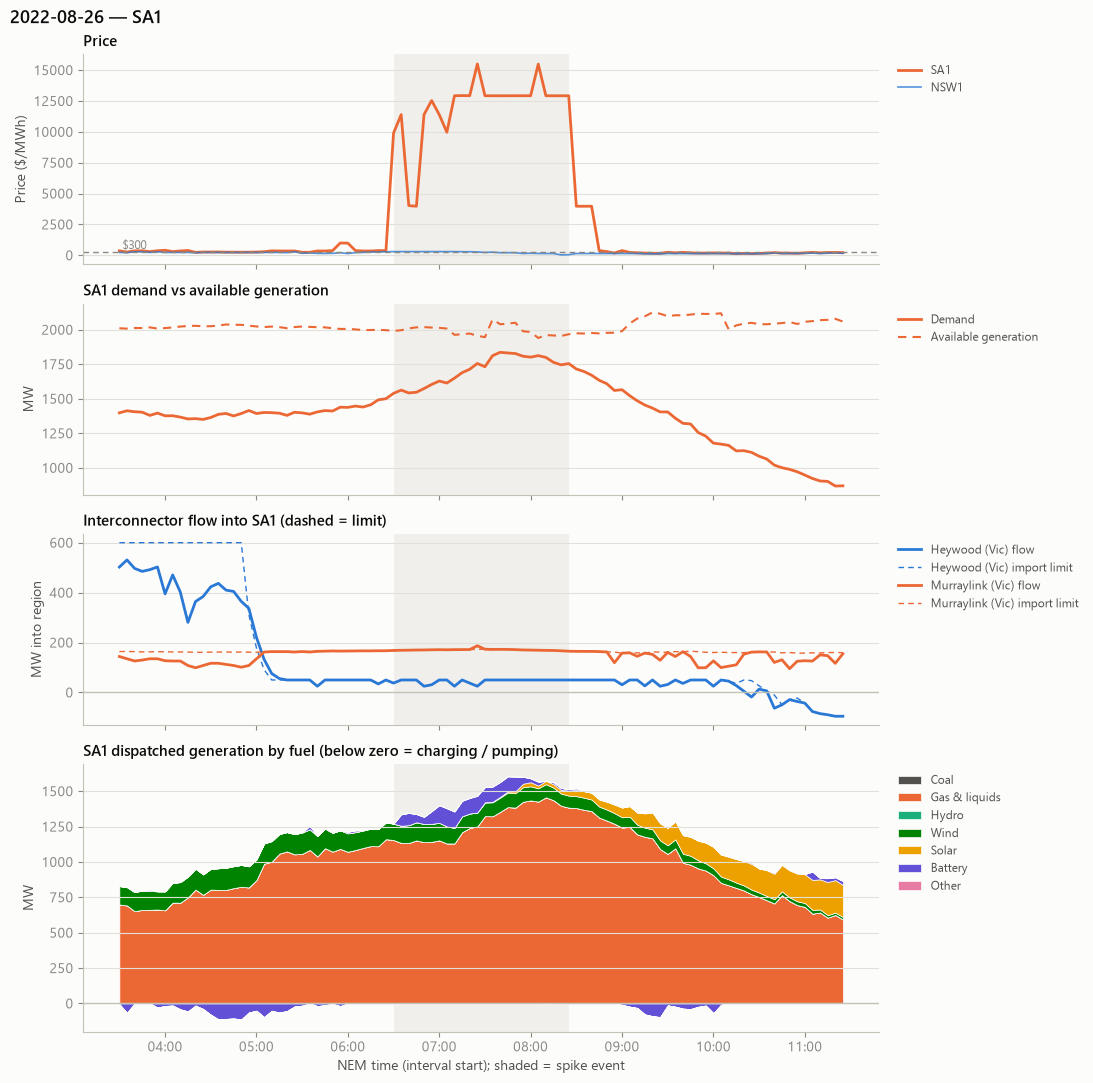

In [12]:
ev = loaded[("2022-08-26_SA1", "SA1")]
fig = plot_event(ev)
save_chart(fig, "../charts/05_event_2022-08-26_sa1.png")

In [13]:
summary = event_summary(ev)
limit_rows = summary.index[summary.index.str.startswith("at limit")]
summary.style.format("{:,.0f}").format("{:.0%}", subset=pd.IndexSlice[limit_rows, :])

,3h before,during spike,change
price,358,"11,939","11,581"
demand,"1,403","1,706",303
available_gen,"2,017","1,993",-23
import: Heywood (Vic),245,45,-200
import: Murraylink (Vic),142,171,29
at limit: Heywood (Vic),39%,100%,61%
at limit: Murraylink (Vic),42%,96%,54%
gen: Coal,0,0,0
gen: Gas & liquids,901,"1,279",379
gen: Hydro,0,0,0


**Desk note (4–5 lines):** _what happened, what drove it (demand / wind / interconnector / outage / bidding), and what a trader would take from it_

## Event: 2024-05-08 — NSW1

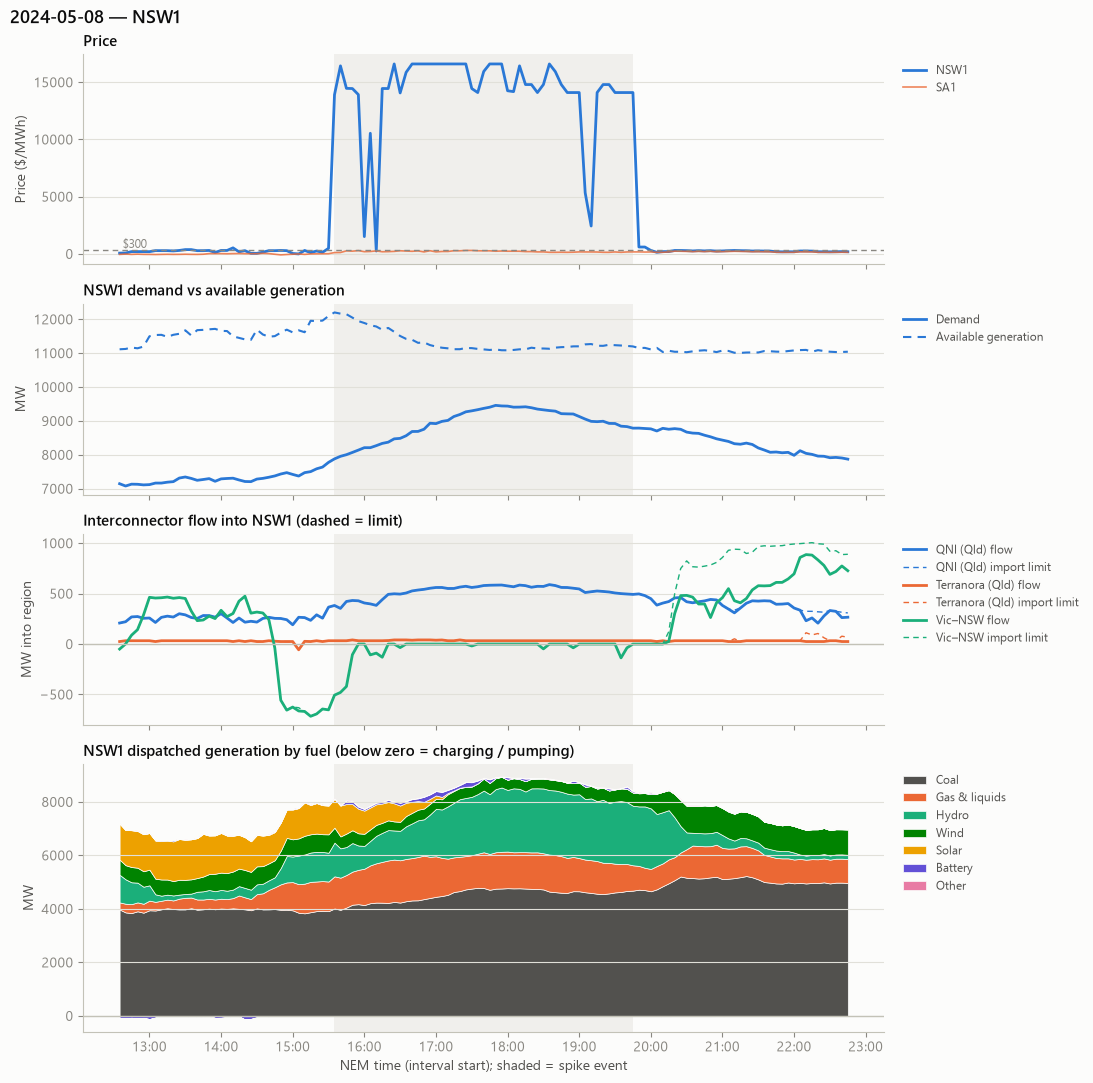

In [14]:
ev = loaded[("2024-05-08_NSW1", "NSW1")]
fig = plot_event(ev)
save_chart(fig, "../charts/05_event_2024-05-08_nsw1.png")

In [15]:
summary = event_summary(ev)
limit_rows = summary.index[summary.index.str.startswith("at limit")]
summary.style.format("{:,.0f}").format("{:.0%}", subset=pd.IndexSlice[limit_rows, :])

,3h before,during spike,change
price,233,"14,158","13,925"
demand,"7,307","8,908","1,601"
available_gen,"11,566","11,350",-216
import: QNI (Qld),258,522,264
import: Terranora (Qld),28,35,7
import: Vic–NSW,58,-42,-100
at limit: QNI (Qld),100%,100%,0%
at limit: Terranora (Qld),100%,100%,0%
at limit: Vic–NSW,97%,100%,3%
gen: Coal,"3,957","4,515",558


**Desk note (4–5 lines):** _what happened, what drove it (demand / wind / interconnector / outage / bidding), and what a trader would take from it_

## Event: 2024-11-27 — NSW1

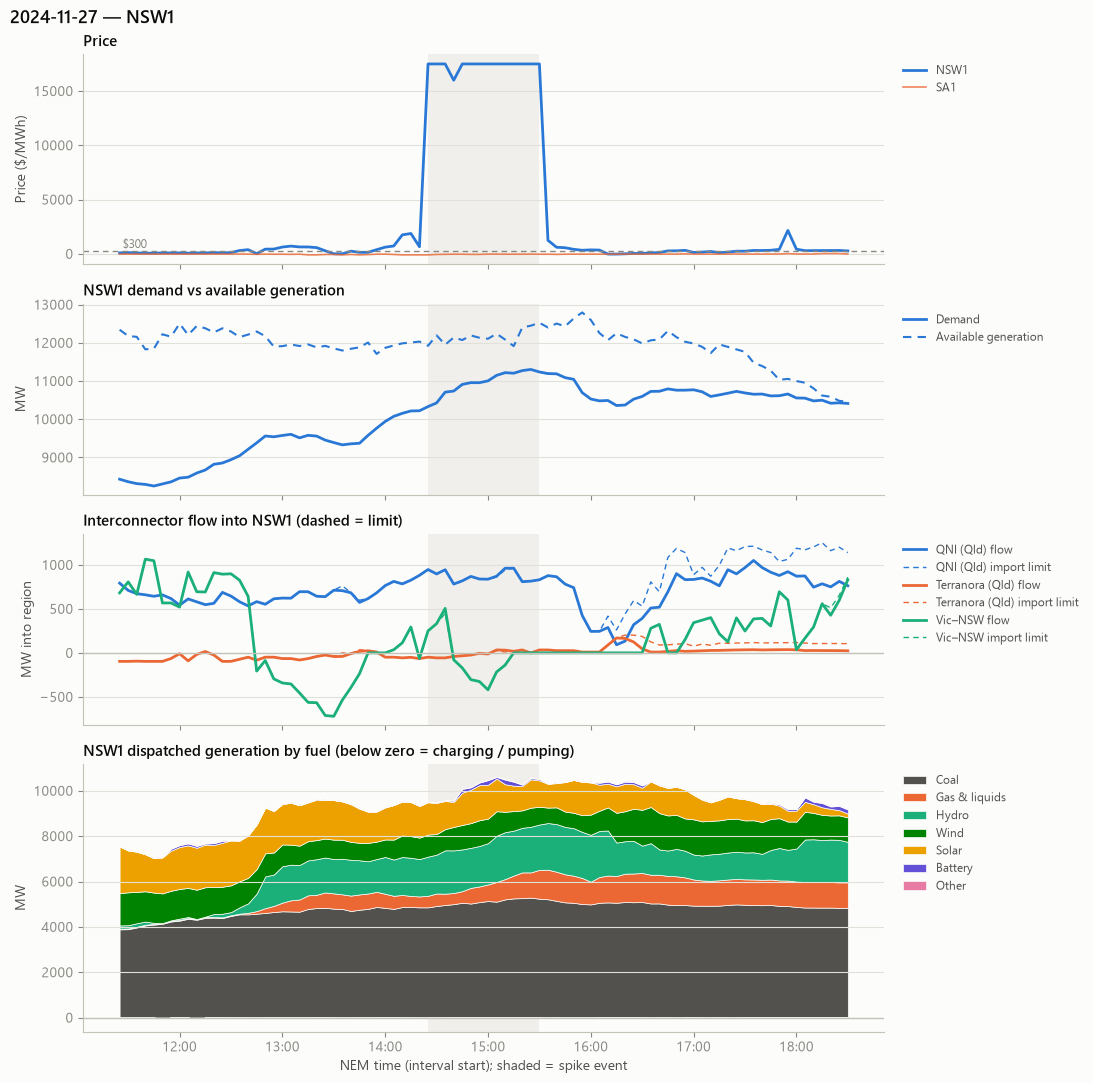

In [16]:
ev = loaded[("2024-11-27_NSW1", "NSW1")]
fig = plot_event(ev)
save_chart(fig, "../charts/05_event_2024-11-27_nsw1.png")

In [17]:
summary = event_summary(ev)
limit_rows = summary.index[summary.index.str.startswith("at limit")]
summary.style.format("{:,.0f}").format("{:.0%}", subset=pd.IndexSlice[limit_rows, :])

,3h before,during spike,change
price,351,"17,393","17,042"
demand,"9,182","10,958","1,776"
available_gen,"12,067","12,166",99
import: QNI (Qld),660,870,210
import: Terranora (Qld),-53,-10,44
import: Vic–NSW,203,-41,-243
at limit: QNI (Qld),94%,86%,-9%
at limit: Terranora (Qld),94%,86%,-9%
at limit: Vic–NSW,100%,79%,-21%
gen: Coal,"4,537","5,103",566


**Desk note (4–5 lines):** _what happened, what drove it (demand / wind / interconnector / outage / bidding), and what a trader would take from it_

## Event: 2025-06-26 — NSW1

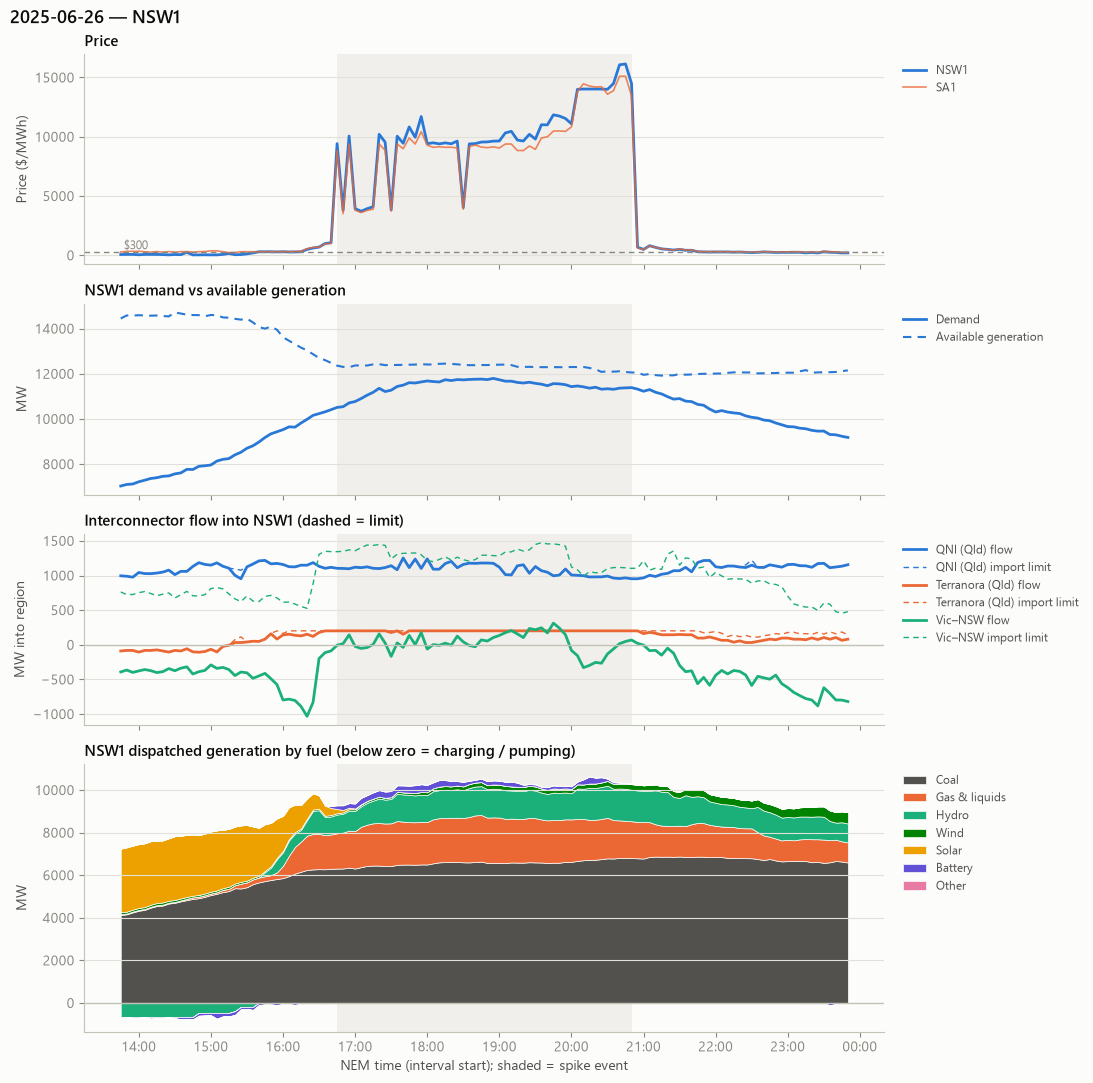

In [18]:
ev = loaded[("2025-06-26_NSW1_SA1", "NSW1")]
fig = plot_event(ev)
save_chart(fig, "../charts/05_event_2025-06-26_nsw1.png")

In [19]:
summary = event_summary(ev)
limit_rows = summary.index[summary.index.str.startswith("at limit")]
summary.style.format("{:,.0f}").format("{:.0%}", subset=pd.IndexSlice[limit_rows, :])

,3h before,during spike,change
price,224,"10,126","9,902"
demand,"8,493","11,447","2,954"
available_gen,"14,108","12,328","-1,780"
import: QNI (Qld),"1,102","1,089",-13
import: Terranora (Qld),12,200,188
import: Vic–NSW,-447,32,479
at limit: QNI (Qld),94%,100%,6%
at limit: Terranora (Qld),69%,96%,27%
at limit: Vic–NSW,0%,0%,0%
gen: Coal,"5,265","6,578","1,312"


**Desk note (4–5 lines):** _what happened, what drove it (demand / wind / interconnector / outage / bidding), and what a trader would take from it_

## Event: 2025-06-26 — SA1

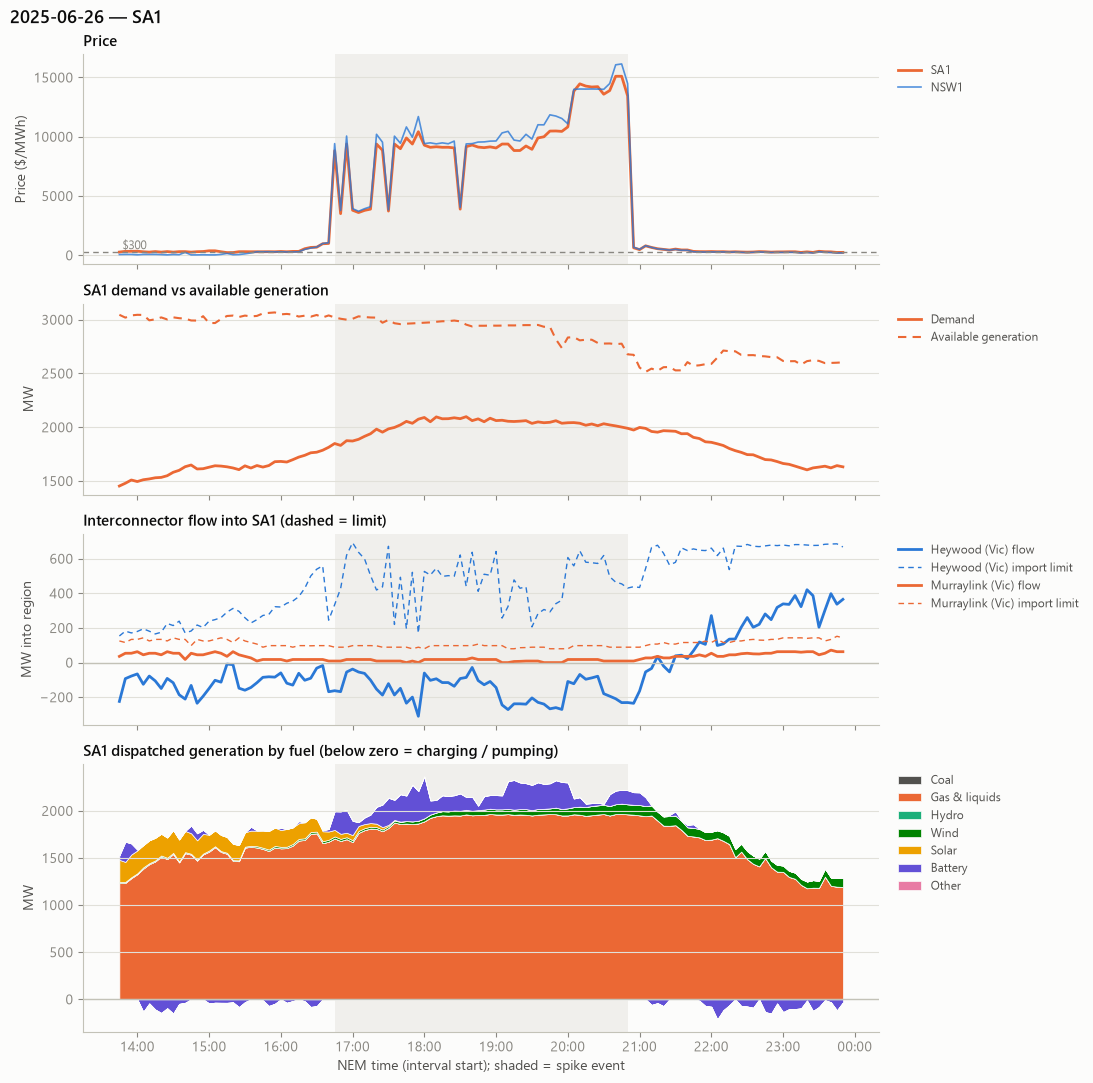

In [20]:
ev = loaded[("2025-06-26_NSW1_SA1", "SA1")]
fig = plot_event(ev)
save_chart(fig, "../charts/05_event_2025-06-26_sa1.png")

In [21]:
summary = event_summary(ev)
limit_rows = summary.index[summary.index.str.startswith("at limit")]
summary.style.format("{:,.0f}").format("{:.0%}", subset=pd.IndexSlice[limit_rows, :])

,3h before,during spike,change
price,371,"9,588","9,217"
demand,"1,627","2,022",395
available_gen,"3,027","2,924",-103
import: Heywood (Vic),-113,-156,-43
import: Murraylink (Vic),37,12,-25
at limit: Heywood (Vic),0%,0%,0%
at limit: Murraylink (Vic),0%,0%,0%
gen: Coal,0,0,0
gen: Gas & liquids,"1,539","1,906",368
gen: Hydro,0,0,0


**Desk note (4–5 lines):** _what happened, what drove it (demand / wind / interconnector / outage / bidding), and what a trader would take from it_

## Event: 2026-01-26 — SA1

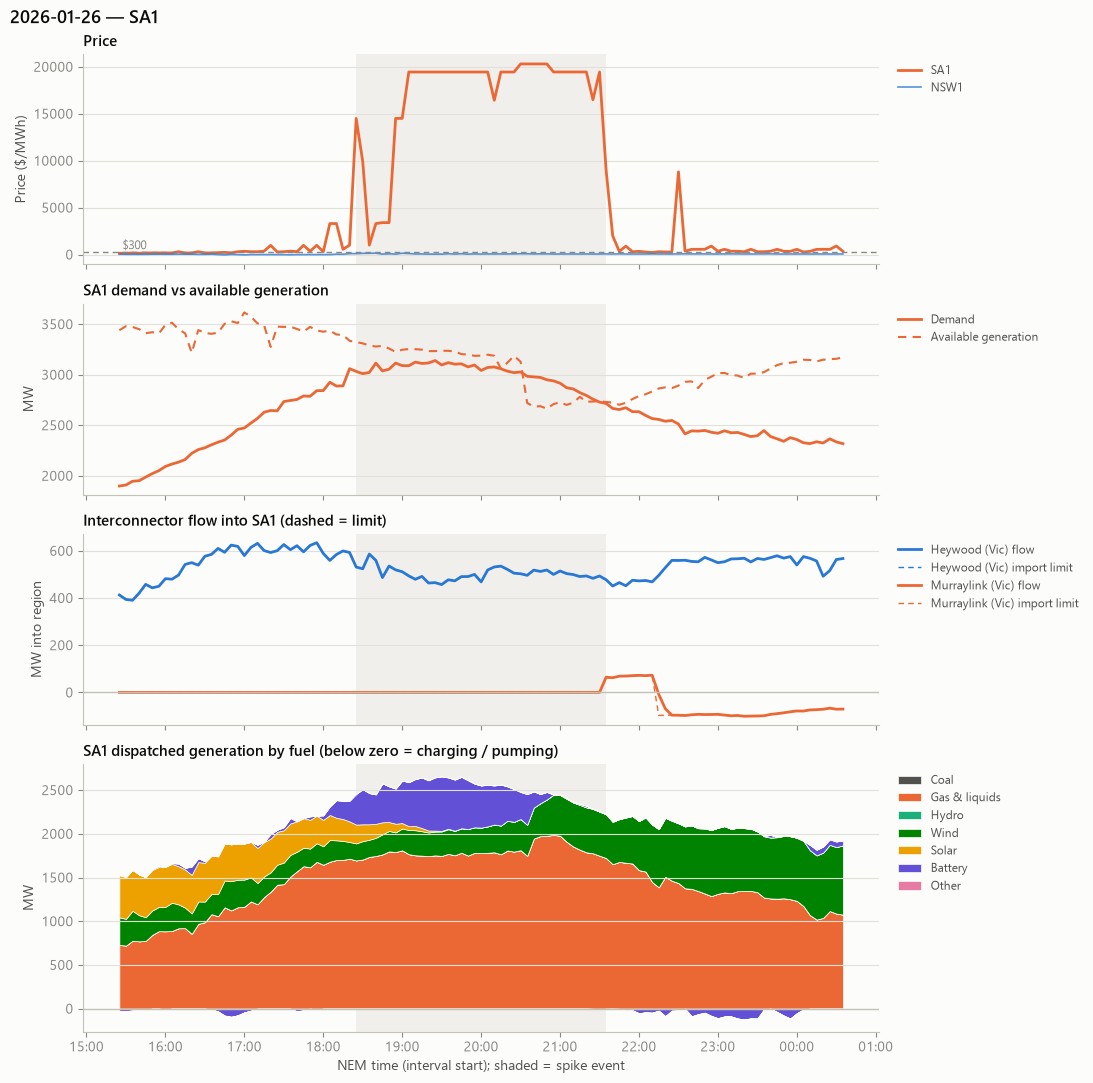

In [22]:
ev = loaded[("2026-01-26_SA1", "SA1")]
fig = plot_event(ev)
save_chart(fig, "../charts/05_event_2026-01-26_sa1.png")

In [23]:
summary = event_summary(ev)
limit_rows = summary.index[summary.index.str.startswith("at limit")]
summary.style.format("{:,.0f}").format("{:.0%}", subset=pd.IndexSlice[limit_rows, :])

,3h before,during spike,change
price,497,"16,797","16,299"
demand,"2,434","3,007",574
available_gen,"3,446","3,055",-391
import: Heywood (Vic),553,503,-50
import: Murraylink (Vic),0,2,2
at limit: Heywood (Vic),100%,100%,0%
at limit: Murraylink (Vic),100%,100%,0%
gen: Coal,0,0,0
gen: Gas & liquids,"1,195","1,799",605
gen: Hydro,0,0,0


**Desk note (4–5 lines):** _what happened, what drove it (demand / wind / interconnector / outage / bidding), and what a trader would take from it_

## Step 3: which interconnectors were actually constrained?

The `EXPORTLIMIT`/`IMPORTLIMIT` columns sit on the flow most of the time, so they can't tell you whether a limit really bit.
The reliable test is AEMO's **binding constraints** (DISPATCHCONSTRAINT, `MARGINALVALUE` ≠ 0): a constraint that contains an
interconnector and binds is actively holding that interconnector's flow back.

`binding_share` = share of the event's spike intervals in which at least one binding constraint contained that interconnector.
Constraint IDs follow AEMO's naming: the first letter is the region (`S_` SA, `N_` NSW, `V_` Vic, `Q_` Qld, `I_` inter-regional),
`F_` constraints are for FCAS, and `#` constraints are unit-specific.

In [24]:
constraint_ics = pd.read_parquet(f"{EVENTS_DIR}/constraint_interconnectors.parquet")
constraint_desc = pd.read_parquet(f"{EVENTS_DIR}/constraint_descriptions.parquet").set_index("GENCONID")


def spike_rows(table, ev, time_col="SETTLEMENTDATE"):
    """Rows of `table` inside the spike (by interval end, matching SETTLEMENTDATE)."""
    end_times = ev["market"].loc[
        (ev["market"]["REGIONID"] == ev["region"])
        & ev["market"]["interval_start"].between(ev["spike_start"], ev["spike_end"]), "SETTLEMENTDATE"]
    return table[table[time_col].isin(end_times)], len(end_times)


def interconnector_binding(ev):
    region_ics = [ic for ic, ends in IC_ENDS.items() if ev["region"] in ends]
    cons = pd.read_parquet(f"{EVENTS_DIR}/{ev['name']}_constraints.parquet")
    cons, n = spike_rows(cons, ev)
    cons = cons[~cons["CONSTRAINTID"].str.startswith("F_")]  # FCAS constraints don't hold back energy flows directly
    hits = cons.merge(constraint_ics, left_on="CONSTRAINTID", right_on="GENCONID")
    hits = hits[hits["INTERCONNECTORID"].isin(region_ics)]
    share = hits.groupby("INTERCONNECTORID")["SETTLEMENTDATE"].nunique() / n
    return share.reindex(region_ics).fillna(0).rename(index=IC_NAME).rename("binding_share").to_frame()


def top_binding_constraints(ev, n_top=8):
    """The constraints that bound most often during the spike, with the interconnectors they contain."""
    cons = pd.read_parquet(f"{EVENTS_DIR}/{ev['name']}_constraints.parquet")
    cons, n = spike_rows(cons, ev)
    summary = cons.groupby("CONSTRAINTID").agg(intervals=("SETTLEMENTDATE", "nunique"),
                                               mean_marginal_value=("MARGINALVALUE", "mean"))
    summary["share_of_spike"] = summary["intervals"] / n
    summary["interconnectors"] = constraint_ics.groupby("GENCONID")["INTERCONNECTORID"].apply(", ".join)
    summary["description"] = constraint_desc["DESCRIPTION"].str.slice(0, 80)
    energy = summary[~summary.index.str.startswith("F_")]  # FCAS constraints don't hold back energy flows directly
    return energy.sort_values(["intervals", "mean_marginal_value"], ascending=[False, True]).head(n_top)


for key, ev in loaded.items():
    print(f"\n=== {key[0][:10]} {key[1]}")
    print(interconnector_binding(ev).to_string(float_format="{:.0%}".format))


=== 2022-08-26 SA1
                  binding_share
INTERCONNECTORID               
Heywood (Vic)               25%
Murraylink (Vic)           100%

=== 2024-05-08 NSW1
                  binding_share
INTERCONNECTORID               
QNI (Qld)                    0%
Terranora (Qld)              0%
Vic–NSW                    100%

=== 2024-11-27 NSW1
                  binding_share
INTERCONNECTORID               
QNI (Qld)                  100%
Terranora (Qld)            100%
Vic–NSW                    100%

=== 2025-06-26 NSW1
                  binding_share
INTERCONNECTORID               
QNI (Qld)                  100%
Terranora (Qld)             94%
Vic–NSW                      0%

=== 2025-06-26 SA1
                  binding_share
INTERCONNECTORID               
Heywood (Vic)                0%
Murraylink (Vic)             0%

=== 2026-01-26 SA1
                  binding_share
INTERCONNECTORID               
Heywood (Vic)              100%
Murraylink (Vic)           100%


In [25]:
ev = loaded[("2026-01-26_SA1", "SA1")]  # change the key to look at another event
top_binding_constraints(ev).style.format({"share_of_spike": "{:.0%}", "mean_marginal_value": "{:,.0f}"})

,intervals,mean_marginal_value,share_of_spike,interconnectors,description
CONSTRAINTID,,,,,
#GPWFWST1_E1,39,"-7,308,000",100%,nan,VGP21G.ENERGY * 1 <= 246 (Wt = 360)
#GPWFWST2_E1,39,"-7,308,000",100%,nan,VGP22G.ENERGY * 1 <= 126 (Wt = 360)
V_BULGANAWF_FLT_0,39,"-710,500",100%,nan,Limit Bulgana Wind Farm upper limit to 0 MW to manage system stability on the ne
VS_600_TEST,39,"-16,101",100%,"V-S-MNSP1, V-SA","Out = Nil, Vic to SA on Heywood limit of 600 MW, limit for testing of Heywood in"
SVML_ZERO,38,"-23,548,000",97%,nan,nan
N^^V_BADP_1,38,-79,97%,"V-S-MNSP1, VIC1-NSW1","Out = Balranald to Darlington Point (X5) 220kV line, avoid voltage collapse at D"
N>>NIL_33_34,34,-87,87%,"N-Q-MNSP1, NSW1-QLD1, VIC1-NSW1","Out= Nil, avoid Bayswater to Liddell (33 or 34) O/L on loss of other Bayswater t"
V^^SML_NSWRB_2,23,"-41,519",59%,V-S-MNSP1,"Out = NSW Murraylink runback scheme, VIC to SA transfer limit on Murraylink to a"


## Step 4: who set the price?

AEMO publishes, for every dispatch interval, the bid band(s) that set each region's price (NEMDE **NemPriceSetter** files —
the same source NEMED uses). Below: for each event's spike intervals, which units set the price most often, with their fuel and the price of the band
that set it. When several units set the price together, each one is counted. A unit in another region means price was set
there and passed through an interconnector.

Some rows name a **combination** (e.g. `COLWF01,ENOF,1,SEBSF1,ENOF,1`) instead of one unit: NEMDE could only set the
price by trading several offers off against each other, usually because a network constraint links them. Those are
grouped as *combination* below; when they dominate an event at the cap, the price came from the constraint, not from a single bid.

In [26]:
def price_setters(ev, n_top=8):
    ps = pd.read_parquet(f"{EVENTS_DIR}/{ev['name']}_pricesetters.parquet")
    ps = ps[ps["RegionID"] == ev["region"]].copy()
    ps.loc[ps["Unit"].str.contains(","), "Unit"] = "(combination of offers)"
    ps, n = spike_rows(ps, ev)
    summary = ps.groupby("Unit").agg(
        intervals=("SETTLEMENTDATE", "nunique"),
        median_band_price=("RRNBandPrice", "median"),
    )
    summary["share_of_spike"] = summary["intervals"] / n
    duid_info = units.set_index("DUID")[["REGIONID", "fuel"]]
    summary = summary.join(duid_info, how="left")
    return summary.sort_values("intervals", ascending=False).head(n_top)


for key, ev in loaded.items():
    print(f"\n=== {key[0][:10]} {key[1]}")
    print(price_setters(ev).to_string(formatters={"share_of_spike": "{:.0%}".format, "median_band_price": "{:,.0f}".format}))


=== 2022-08-26 SA1
                         intervals median_band_price share_of_spike REGIONID           fuel
Unit                                                                                       
BARKIPS1                        14            12,922            58%      SA1  Gas & liquids
HPRG1                            4            11,397            17%      SA1        Battery
LBBG1                            3                 8            12%      SA1        Battery
WALGRVG1                         3                20            12%     NSW1        Battery
(combination of offers)          2                 0             8%      NaN            NaN
VP6                              2                 8             8%     NSW1           Coal
GORDON                           2                 1             8%     TAS1          Hydro
MP2                              2                27             8%     NSW1           Coal

=== 2024-05-08 NSW1
                         intervals medi

**Add to each desk note** the constraint that held the region back (if any) and the unit(s) that set the price,
e.g. *"Heywood was held at ~500 MW by a binding Vic–SA constraint for 90% of the event; Torrens Island battery's top band at ~$19,400 set the price."*